# CNT-12 Project Notebook: Trade Flows and Supply Chain Dependency

**Live walkthrough version.** Run the cells from top to bottom. The notebook reads the saved UN Comtrade data in `data/raw`; it does not download anything.

Before starting, select the project's `.venv` Python interpreter in VS Code or Jupyter. The analysis writes its figures to `reports/figures` and its tables to `reports/tables`.

This notebook covers all four analytics stages:

1. **Descriptive** — trade trends, supplier shares, and concentration.
2. **Diagnostic** — HS6 product and supplier decomposition.
3. **Predictive** — 2026–2028 import forecast with validation.
4. **Prescriptive** — supplier-diversification scenarios for 2028.

> If a cell fails, re-run the notebook from the top. The cells are sequential and share variables.

# 1. Project definition

## Selected analytics type

The first stage of this project uses **descriptive analytics**. Descriptive analytics is appropriate because a reliable account of the size, direction, composition, and concentration of India's semiconductor trade is needed before attempting diagnostic, predictive, or prescriptive work.

## Specific question

> How did India's imports and exports of electronic integrated circuits change between 2019 and 2025, and how concentrated were India's imports among supplier countries or areas in the latest year?

The unit of analysis is India at the country level. The selected sector is electronic integrated circuits, represented by Harmonized System code **HS 8542**. The analysis measures annual trade value, trade balance, supplier market shares, the Herfindahl-Hirschman Index (HHI), and top-supplier concentration ratios.

## Required dataset

The project requires annual merchandise-trade records with the following fields:

| Field | Purpose |
|---|---|
| Reporting country and year | Define India and the 2019-2025 study period |
| Trade flow | Separate imports from exports |
| Partner country | Identify suppliers and destinations |
| HS commodity code | Restrict the analysis to electronic integrated circuits |
| Trade value in US dollars | Measure flows and calculate supplier shares |
| Net weight | Provide a physical-volume field where available |

The data source is the **United Nations Comtrade Database**. The query uses India as reporter (Comtrade reporter code 699), imports and exports as flows, all available partners, annual frequency, and HS 8542. UN Comtrade is selected because it provides a documented official source for bilateral merchandise trade.

Source documentation: <https://uncomtrade.org/docs/un-comtrade-api/>

## Dataset access plan

1. Use the public UN Comtrade preview API, which does not require an API key.
2. Submit one request for each year because the preview API accepts one period and one product per call.
3. Request both import and export flows for India and HS 8542, retaining the World aggregate and individual partner records.
4. Join partner codes to the official Comtrade partner-area reference file.
5. Reject any query that reaches the 500-record preview limit, because that could indicate truncation.
6. Save selected source fields in `data/raw` without analytical transformations, together with retrieval metadata and the exact query URLs.
7. Clean and validate the data in Python, then save derived tables and figures so the results can be reproduced.

The acquisition command used for this notebook is:

```bash
python scripts/data_acquisition.py
```

# 2. Python environment and data loading

All data preparation, analysis, and visualisation are performed in Python. This Jupyter notebook is the cell-by-cell walkthrough; the R Markdown version produces the final HTML and PDF report.

In [1]:
%matplotlib inline
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

# Make the notebook work whether it is opened from the repo root or notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)

DATA_PATH = Path("data/raw/india_hs8542_trade_2019_2025.csv")
DETAIL_PATH = Path("data/raw/india_hs8542_hs6_imports_2019_2025.csv")
PROCESSED_DIR = Path("data/processed")
FIGURE_DIR = Path("reports/figures")
TABLE_DIR = Path("reports/tables")

for directory in (PROCESSED_DIR, FIGURE_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print(f"Working directory: {Path.cwd()}")
print(f"Python {os.sys.version.split()[0]}")
print(f"pandas {pd.__version__}, numpy {np.__version__}, scipy {scipy.__version__}")

Working directory: C:\Users\soumy\OneDrive\Desktop\Projects\5th Sem Project HoD\Trade-Flows-and-Supply-Chain-Dependency
Python 3.13.7
pandas 2.2.3, numpy 2.2.6, scipy 1.14.1


In [2]:
trade = pd.read_csv(DATA_PATH)

numeric_columns = [
    "year", "reporter_code", "partner_code", "trade_value_usd", "net_weight_kg"
]
for column in numeric_columns:
    trade[column] = pd.to_numeric(trade[column], errors="coerce")

trade["year"] = trade["year"].astype("Int64")
trade["trade_value_usd"] = trade["trade_value_usd"].fillna(0.0)
trade["partner_iso3"] = trade["partner_iso3"].fillna("")
trade["partner_name"] = trade["partner_name"].fillna(
    "Partner " + trade["partner_code"].astype("Int64").astype(str)
)

print(f"Rows: {len(trade):,}")
print(f"Years: {trade['year'].min()}-{trade['year'].max()}")
print(f"Flows: {', '.join(sorted(trade['flow_name'].unique()))}")
print(f"Missing trade values: {trade['trade_value_usd'].isna().sum()}")

Rows: 1,443
Years: 2019-2025
Flows: Export, Import
Missing trade values: 0


# 3. Data quality checks

The World record is an aggregate national total. It is used for trend and trade-balance analysis but excluded from supplier shares to prevent double counting. Group partners are also excluded from country-level supplier concentration.

In [3]:
expected_years = set(range(2019, 2026))
observed_years = set(trade["year"].dropna().astype(int))
assert observed_years == expected_years, "The expected annual coverage is incomplete."
assert set(trade["flow_code"]) == {"M", "X"}, "Both trade flows are required."
assert (trade["hs_code"].astype(str) == "8542").all(), "Unexpected HS code found."
assert (trade["reporter_name"] == "India").all(), "Unexpected reporter found."
assert (trade["trade_value_usd"] >= 0).all(), "Negative trade value found."

key = ["year", "flow_code", "partner_code"]
duplicate_count = int(trade.duplicated(key).sum())
world_counts = (
    trade.loc[trade["partner_code"] == 0]
    .groupby(["year", "flow_code"])
    .size()
)
assert duplicate_count == 0, "Duplicate country-flow-year records found."
assert (world_counts == 1).all(), "Each year and flow needs one World total."

bilateral_totals = (
    trade.loc[(trade["partner_code"] != 0) & (~trade["partner_is_group"].astype(bool))]
    .groupby(["year", "flow_code"])["trade_value_usd"]
    .sum()
)
world_totals = (
    trade.loc[trade["partner_code"] == 0]
    .set_index(["year", "flow_code"])["trade_value_usd"]
)
largest_reconciliation_gap = float(
    ((bilateral_totals - world_totals).abs() / world_totals).max()
)
assert largest_reconciliation_gap < 0.001, "Partner records do not reconcile to World totals."

quality_summary = pd.DataFrame(
    {
        "check": [
            "Rows", "Duplicate keys", "Missing trade values",
            "Minimum year", "Maximum year", "Distinct partner labels",
            "Largest partner-total gap (%)"
        ],
        "result": [
            len(trade), duplicate_count, int(trade["trade_value_usd"].isna().sum()),
            int(trade["year"].min()), int(trade["year"].max()),
            int(trade["partner_name"].nunique()), largest_reconciliation_gap * 100
        ],
    }
)
print(quality_summary.to_string(index=False))

                        check   result
                         Rows 1,443.00
               Duplicate keys     0.00
         Missing trade values     0.00
                 Minimum year 2,019.00
                 Maximum year 2,025.00
      Distinct partner labels   188.00
Largest partner-total gap (%)     0.00


In [4]:
world = trade.loc[trade["partner_code"] == 0].copy()
bilateral = trade.loc[
    (trade["partner_code"] != 0) & (~trade["partner_is_group"].astype(bool))
].copy()

trade.to_csv(PROCESSED_DIR / "india_hs8542_trade_clean.csv", index=False)

# 4. Descriptive results

## 4.1 Import and export trend

In [5]:
yearly = (
    world.pivot(index="year", columns="flow_name", values="trade_value_usd")
    .reset_index()
    .rename_axis(None, axis=1)
)
yearly["trade_balance_usd"] = yearly["Export"] - yearly["Import"]
yearly["import_yoy_percent"] = yearly["Import"].pct_change() * 100
yearly["export_yoy_percent"] = yearly["Export"].pct_change() * 100

periods = int(yearly["year"].max() - yearly["year"].min())
import_cagr = (yearly["Import"].iloc[-1] / yearly["Import"].iloc[0]) ** (1 / periods) - 1
export_cagr = (yearly["Export"].iloc[-1] / yearly["Export"].iloc[0]) ** (1 / periods) - 1

yearly.to_csv(TABLE_DIR / "yearly_trade_summary.csv", index=False)
print(yearly.to_string(index=False))
print(f"Import CAGR: {import_cagr:.1%}")
print(f"Export CAGR: {export_cagr:.1%}")

 year         Export            Import  trade_balance_usd  import_yoy_percent  export_yoy_percent
 2019 247,943,980.86 10,172,390,321.80  -9,924,446,340.95                 NaN                 NaN
 2020 265,331,454.59  8,417,890,350.81  -8,152,558,896.22              -17.25                7.01
 2021 380,462,791.50 12,391,531,711.14 -12,011,068,919.65               47.20               43.39
 2022 476,192,970.41 16,122,209,275.13 -15,646,016,304.72               30.11               25.16
 2023 215,103,208.18 19,215,450,431.30 -19,000,347,223.12               19.19              -54.83
 2024 267,771,046.73 23,445,487,573.73 -23,177,716,527.00               22.01               24.48
 2025 242,000,298.25 28,616,482,893.97 -28,374,482,595.72               22.06               -9.62
Import CAGR: 18.8%
Export CAGR: -0.4%


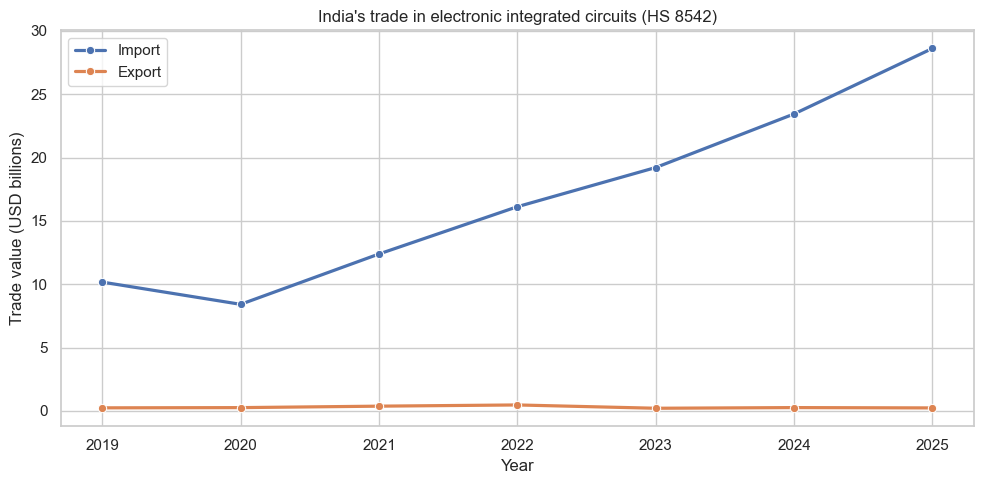

In [6]:
trend_long = yearly.melt(
    id_vars="year", value_vars=["Import", "Export"],
    var_name="Flow", value_name="Trade value (USD)"
)
trend_long["Trade value (USD billions)"] = trend_long["Trade value (USD)"] / 1e9

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=trend_long, x="year", y="Trade value (USD billions)",
    hue="Flow", marker="o", linewidth=2.3, ax=ax
)
ax.set(
    title="India's trade in electronic integrated circuits (HS 8542)",
    xlabel="Year", ylabel="Trade value (USD billions)"
)
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "trade_trend.png", dpi=180, bbox_inches="tight")
plt.show()

## 4.2 Supplier concentration in the latest year

Supplier shares are calculated only after aggregating trade value by partner country or area. HHI is the sum of squared percentage shares and ranges from near zero to 10,000. A larger value indicates that imports are concentrated among fewer sources.

In [7]:
latest_year = int(trade["year"].max())
latest_imports = bilateral.loc[
    (bilateral["year"] == latest_year) & (bilateral["flow_code"] == "M")
]

suppliers = (
    latest_imports.groupby(["partner_code", "partner_iso3", "partner_name"], as_index=False)
    ["trade_value_usd"].sum()
    .sort_values("trade_value_usd", ascending=False)
)
suppliers["supplier_share_percent"] = (
    suppliers["trade_value_usd"] / suppliers["trade_value_usd"].sum() * 100
)
suppliers["cumulative_share_percent"] = suppliers["supplier_share_percent"].cumsum()

hhi = float((suppliers["supplier_share_percent"] ** 2).sum())
effective_suppliers = 1 / float((suppliers["supplier_share_percent"] / 100).pow(2).sum())
top_1_share = float(suppliers["supplier_share_percent"].head(1).sum())
top_3_share = float(suppliers["supplier_share_percent"].head(3).sum())
top_5_share = float(suppliers["supplier_share_percent"].head(5).sum())

suppliers.to_csv(TABLE_DIR / f"import_suppliers_{latest_year}.csv", index=False)

concentration = pd.DataFrame(
    {
        "metric": ["HHI", "Effective number of suppliers", "Top 1 share (%)", "Top 3 share (%)", "Top 5 share (%)"],
        "value": [hhi, effective_suppliers, top_1_share, top_3_share, top_5_share],
    }
)
concentration.to_csv(TABLE_DIR / f"concentration_metrics_{latest_year}.csv", index=False)

print(f"Latest year: {latest_year}")
print(concentration.to_string(index=False))
print("\nTen largest suppliers:")
print(suppliers.head(10).to_string(index=False))

Latest year: 2025
                       metric    value
                          HHI 2,752.77
Effective number of suppliers     3.63
              Top 1 share (%)    40.92
              Top 3 share (%)    85.05
              Top 5 share (%)    91.15

Ten largest suppliers:
 partner_code partner_iso3         partner_name   trade_value_usd  supplier_share_percent  cumulative_share_percent
          156          CHN                China 11,710,232,694.19                   40.92                     40.92
          490          S19      Other Asia, nes  8,046,184,379.77                   28.12                     69.04
          410          KOR        Rep. of Korea  4,580,707,625.56                   16.01                     85.05
          392          JPN                Japan  1,083,699,931.03                    3.79                     88.83
          702          SGP            Singapore    663,029,566.88                    2.32                     91.15
          484          MEX  

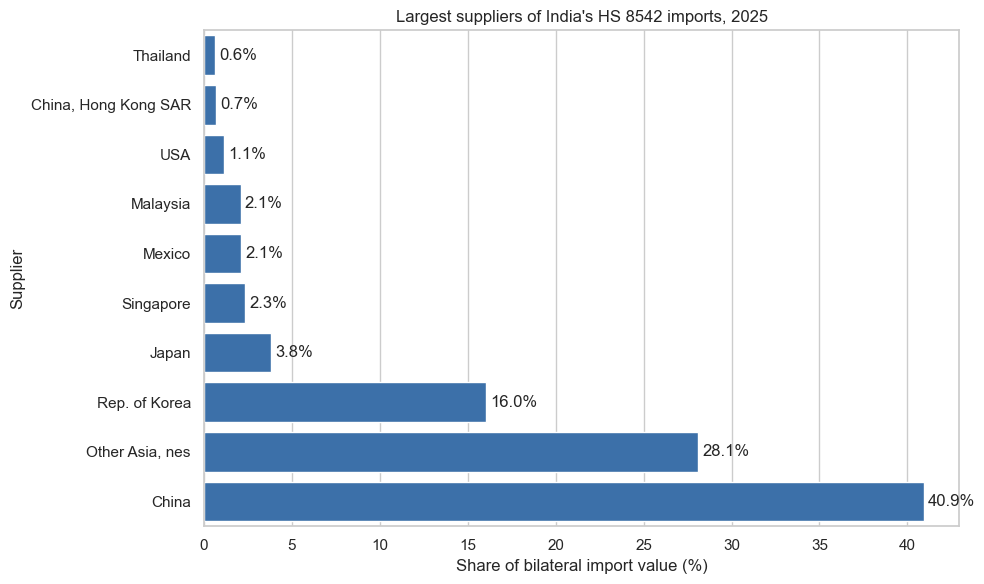

In [8]:
top_suppliers = suppliers.head(10).sort_values("supplier_share_percent")

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_suppliers, x="supplier_share_percent", y="partner_name",
    color="#2a6fbb", ax=ax
)
ax.set(
    title=f"Largest suppliers of India's HS 8542 imports, {latest_year}",
    xlabel="Share of bilateral import value (%)", ylabel="Supplier"
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"import_supplier_share_{latest_year}.png", dpi=180, bbox_inches="tight")
plt.show()

## 4.3 Trade balance

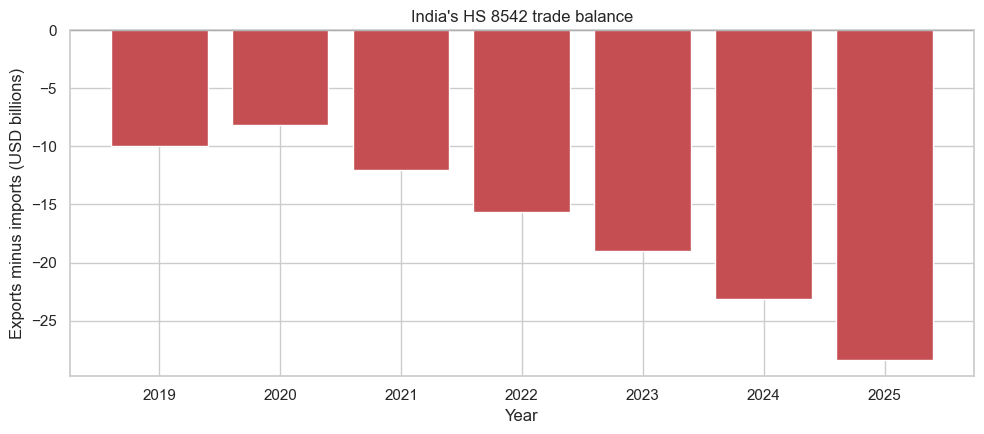

In [9]:
balance_plot = yearly.copy()
balance_plot["Trade balance (USD billions)"] = balance_plot["trade_balance_usd"] / 1e9

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = np.where(balance_plot["trade_balance_usd"] >= 0, "#2e8b57", "#c44e52")
ax.bar(balance_plot["year"].astype(str), balance_plot["Trade balance (USD billions)"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="India's HS 8542 trade balance",
    xlabel="Year", ylabel="Exports minus imports (USD billions)"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "trade_balance.png", dpi=180, bbox_inches="tight")
plt.show()

# 5. Findings and interpretation

India's HS 8542 imports increased from **USD 10.17 billion in 2019 to USD 28.62 billion in 2025**, an annualised growth rate of **18.8%**. Exports changed from **USD 247.94 million to USD 242.00 million**, an annualised rate of **-0.4%**. The trade deficit consequently widened from **USD 9.92 billion to USD 28.37 billion**.

Imports were concentrated among a small number of sources in 2025. China supplied **40.9%**, the Comtrade area labelled **Other Asia, nes** supplied **28.1%**, and the Republic of Korea supplied **16.0%** of bilateral import value. These three sources together accounted for **85.0%**. The HHI was **2,752.8**, equivalent to approximately **3.6 equally sized suppliers**.

The World aggregate is used for national totals, while concentration measures use only non-group bilateral partners. This distinction prevents the World total from being counted as if it were an additional supplier. The individual partner records reconcile to the World totals within rounding precision.

These findings establish the descriptive baseline required for CNT-12. They do not by themselves establish the probability of disruption, the financial exposure of a particular firm, or the best alternative supplier.

# 6. Diagnostic extension

## Diagnostic question

The second stage uses **diagnostic analytics through accounting decomposition**. It asks:

> Which changes in supplier economies and HS six-digit product categories account for the growth and changing concentration of India's electronic-integrated-circuit imports between 2019 and 2025?

This stage decomposes the observed change but does not claim that the data establish economic causality. It uses five HS six-digit categories within HS 8542: processors and controllers (854231), memories (854232), amplifiers (854233), other integrated circuits (854239), and parts (854290).

## 6.1 Detailed data validation

The acquisition script requests each year-product combination separately. The five World totals are summed and reconciled to the HS 8542 World import total already used in the descriptive stage.

In [10]:
detail = pd.read_csv(DETAIL_PATH)
for column in numeric_columns:
    detail[column] = pd.to_numeric(detail[column], errors="coerce")

detail["year"] = detail["year"].astype("Int64")
detail["hs_code"] = detail["hs_code"].astype(str)
detail["trade_value_usd"] = detail["trade_value_usd"].fillna(0.0)
detail["partner_iso3"] = detail["partner_iso3"].fillna("")

expected_codes = {"854231", "854232", "854233", "854239", "854290"}
assert set(detail["hs_code"]) == expected_codes
assert set(detail["year"].dropna().astype(int)) == expected_years
assert set(detail["flow_code"]) == {"M"}
assert int(detail.duplicated(["year", "hs_code", "partner_code"]).sum()) == 0

detail_world = detail.loc[detail["partner_code"] == 0].copy()
detail_bilateral = detail.loc[
    (detail["partner_code"] != 0) & (~detail["partner_is_group"].astype(bool))
].copy()

detail_world_totals = detail_world.groupby("year")["trade_value_usd"].sum()
heading_import_totals = world.loc[world["flow_code"] == "M"].set_index("year")["trade_value_usd"]
detail_reconciliation = pd.DataFrame(
    {
        "hs6_sum_usd": detail_world_totals,
        "hs8542_total_usd": heading_import_totals,
    }
)
detail_reconciliation["difference_percent"] = (
    (detail_reconciliation["hs6_sum_usd"] - detail_reconciliation["hs8542_total_usd"])
    / detail_reconciliation["hs8542_total_usd"] * 100
)
assert detail_reconciliation["difference_percent"].abs().max() < 0.001

detail.to_csv(PROCESSED_DIR / "india_hs8542_hs6_imports_clean.csv", index=False)
print(f"Detailed rows: {len(detail):,}")
print(detail_reconciliation.to_string())

Detailed rows: 1,749
           hs6_sum_usd  hs8542_total_usd  difference_percent
year                                                        
2019 10,172,390,321.80 10,172,390,321.80               -0.00
2020  8,417,890,350.81  8,417,890,350.81               -0.00
2021 12,391,531,711.14 12,391,531,711.14                0.00
2022 16,122,209,275.13 16,122,209,275.13                0.00
2023 19,215,450,431.30 19,215,450,431.30                0.00
2024 23,445,487,573.73 23,445,487,573.73               -0.00
2025 28,616,482,893.97 28,616,482,893.97               -0.00


## 6.2 Product contribution to import growth

In [11]:
product_year = (
    detail_world.groupby(["year", "hs_code", "commodity"], as_index=False)
    ["trade_value_usd"].sum()
)
product_pivot = product_year.pivot(
    index=["hs_code", "commodity"], columns="year", values="trade_value_usd"
).fillna(0)

product_drivers = product_pivot[[2019, 2025]].copy()
product_drivers.columns = ["value_2019_usd", "value_2025_usd"]
product_drivers["value_change_usd"] = (
    product_drivers["value_2025_usd"] - product_drivers["value_2019_usd"]
)
product_drivers["growth_contribution_percent"] = (
    product_drivers["value_change_usd"] / product_drivers["value_change_usd"].sum() * 100
)
product_drivers["share_2019_percent"] = (
    product_drivers["value_2019_usd"] / product_drivers["value_2019_usd"].sum() * 100
)
product_drivers["share_2025_percent"] = (
    product_drivers["value_2025_usd"] / product_drivers["value_2025_usd"].sum() * 100
)
product_drivers = product_drivers.reset_index().sort_values(
    "value_change_usd", ascending=False
)
product_drivers.to_csv(
    TABLE_DIR / "product_growth_drivers_2019_2025.csv", index=False
)
print(product_drivers.to_string(index=False))

hs_code                               commodity   value_2019_usd    value_2025_usd  value_change_usd  growth_contribution_percent  share_2019_percent  share_2025_percent
 854231              Processors and controllers 5,313,237,218.49 16,575,852,286.54 11,262,615,068.06                        61.06               52.23               57.92
 854232                                Memories 1,461,615,714.86  6,026,351,754.90  4,564,736,040.04                        24.75               14.37               21.06
 854239    Other electronic integrated circuits 2,412,800,458.72  5,362,545,005.19  2,949,744,546.47                        15.99               23.72               18.74
 854233                              Amplifiers    39,183,674.32    588,137,826.10    548,954,151.78                         2.98                0.39                2.06
 854290 Parts of electronic integrated circuits   945,553,255.41     63,596,021.24   -881,957,234.17                        -4.78                9.30 

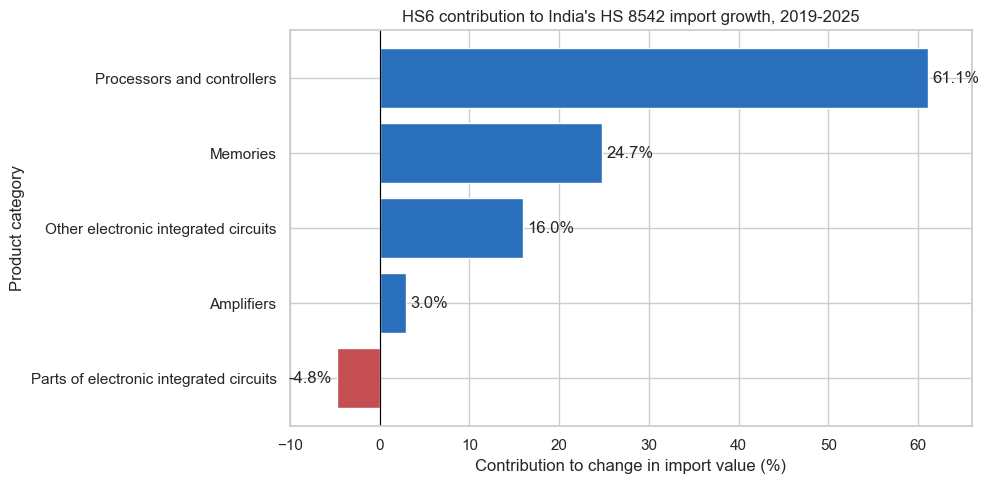

In [12]:
product_plot = product_drivers.sort_values("growth_contribution_percent")
product_colors = np.where(
    product_plot["growth_contribution_percent"] >= 0, "#2a6fbb", "#c44e52"
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    product_plot["commodity"], product_plot["growth_contribution_percent"],
    color=product_colors
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-10, 66)
for bar, value in zip(bars, product_plot["growth_contribution_percent"]):
    offset = 0.5 if value >= 0 else -0.5
    ax.text(
        value + offset, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%",
        va="center", ha="left" if value >= 0 else "right"
    )
ax.set(
    title="HS6 contribution to India's HS 8542 import growth, 2019-2025",
    xlabel="Contribution to change in import value (%)", ylabel="Product category"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "product_growth_contribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 6.3 Supplier concentration and share shifts

In [13]:
supplier_year = (
    detail_bilateral.groupby(
        ["year", "partner_code", "partner_iso3", "partner_name"], as_index=False
    )["trade_value_usd"].sum()
)
supplier_year["supplier_share_percent"] = supplier_year.groupby("year")[
    "trade_value_usd"
].transform(lambda values: values / values.sum() * 100)

hhi_by_year = (
    supplier_year.groupby("year")["supplier_share_percent"]
    .apply(lambda values: float((values**2).sum()))
    .reset_index(name="hhi")
)
hhi_by_year.to_csv(TABLE_DIR / "supplier_hhi_by_year.csv", index=False)

supplier_values = supplier_year.pivot(
    index=["partner_code", "partner_iso3", "partner_name"],
    columns="year", values="trade_value_usd"
).fillna(0)
supplier_shares = supplier_year.pivot(
    index=["partner_code", "partner_iso3", "partner_name"],
    columns="year", values="supplier_share_percent"
).fillna(0)

supplier_drivers = pd.DataFrame(
    {
        "value_2019_usd": supplier_values.get(2019, 0),
        "value_2025_usd": supplier_values.get(2025, 0),
        "share_2019_percent": supplier_shares.get(2019, 0),
        "share_2025_percent": supplier_shares.get(2025, 0),
    }
).reset_index()
supplier_drivers["value_change_usd"] = (
    supplier_drivers["value_2025_usd"] - supplier_drivers["value_2019_usd"]
)
supplier_drivers["share_change_points"] = (
    supplier_drivers["share_2025_percent"] - supplier_drivers["share_2019_percent"]
)
supplier_drivers["hhi_contribution_change"] = (
    supplier_drivers["share_2025_percent"] ** 2
    - supplier_drivers["share_2019_percent"] ** 2
)
supplier_drivers["absolute_share_change"] = supplier_drivers[
    "share_change_points"
].abs()
supplier_drivers = supplier_drivers.sort_values(
    "hhi_contribution_change", ascending=False
)
supplier_drivers.to_csv(
    TABLE_DIR / "supplier_concentration_drivers_2019_2025.csv", index=False
)

print(hhi_by_year.to_string(index=False))
print("\nLargest positive HHI contributions:")
print(supplier_drivers.head(8).to_string(index=False))
print("\nLargest offsetting HHI contributions:")
print(supplier_drivers.tail(8).sort_values("hhi_contribution_change").to_string(index=False))

 year      hhi
 2019 2,753.07
 2020 2,420.47
 2021 2,402.47
 2022 1,949.48
 2023 3,333.98
 2024 2,986.61
 2025 2,752.77

Largest positive HHI contributions:
 partner_code partner_iso3    partner_name   value_2019_usd    value_2025_usd  share_2019_percent  share_2025_percent  value_change_usd  share_change_points  hhi_contribution_change  absolute_share_change
          490          S19 Other Asia, nes    93,289,756.04  8,046,184,379.77                0.92               28.12  7,952,894,623.73                27.20                   789.74                  27.20
          156          CHN           China 3,593,456,939.62 11,710,232,694.19               35.33               40.92  8,116,775,754.57                 5.60                   426.65                   5.60
          410          KOR   Rep. of Korea 1,465,748,220.75  4,580,707,625.56               14.41               16.01  3,114,959,404.81                 1.60                    48.61                   1.60
          392          

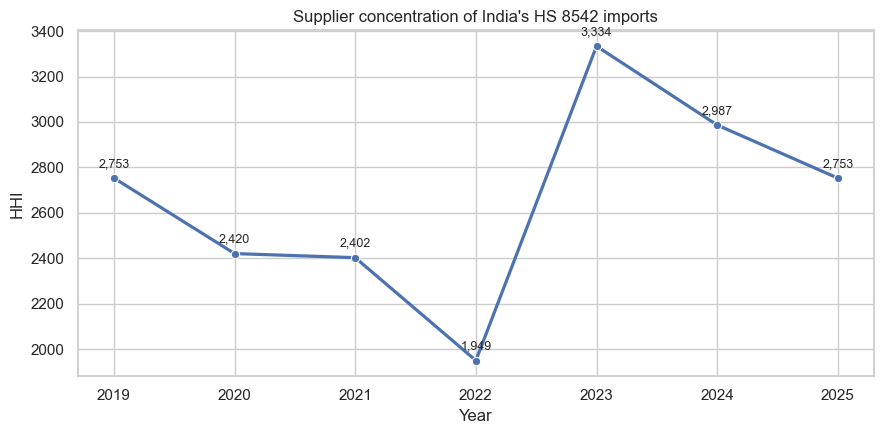

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=hhi_by_year, x="year", y="hhi", marker="o", linewidth=2.3, ax=ax)
for row in hhi_by_year.itertuples(index=False):
    ax.annotate(f"{row.hhi:,.0f}", (row.year, row.hhi), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(
    title="Supplier concentration of India's HS 8542 imports",
    xlabel="Year", ylabel="HHI"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "supplier_hhi_trend.png", dpi=180, bbox_inches="tight")
plt.show()

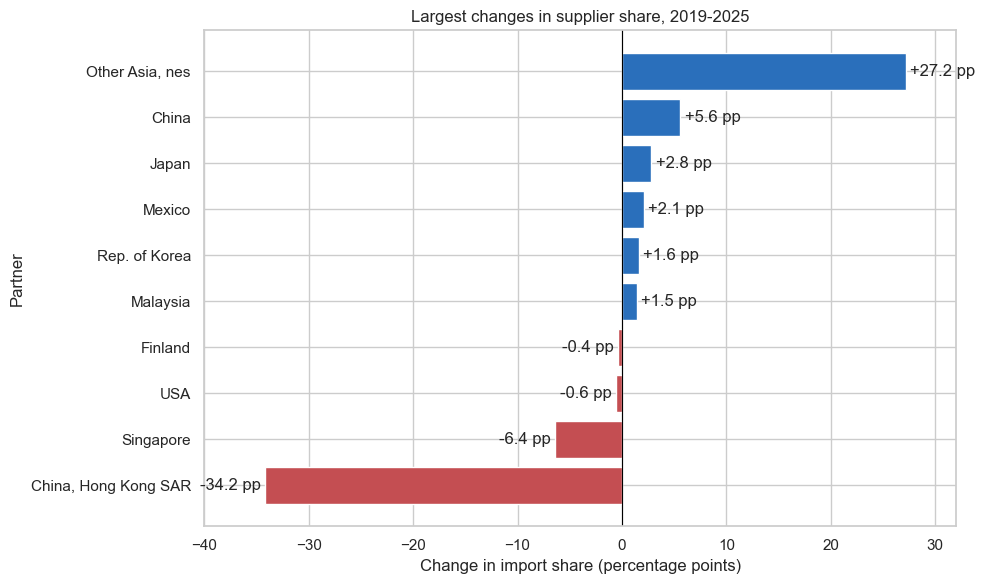

In [15]:
largest_shifts = (
    supplier_drivers.nlargest(10, "absolute_share_change")
    .sort_values("share_change_points")
)
shift_colors = np.where(
    largest_shifts["share_change_points"] >= 0, "#2a6fbb", "#c44e52"
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    largest_shifts["partner_name"], largest_shifts["share_change_points"],
    color=shift_colors
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-40, 32)
for bar, value in zip(bars, largest_shifts["share_change_points"]):
    offset = 0.4 if value >= 0 else -0.4
    ax.text(
        value + offset, bar.get_y() + bar.get_height() / 2, f"{value:+.1f} pp",
        va="center", ha="left" if value >= 0 else "right"
    )
ax.set(
    title="Largest changes in supplier share, 2019-2025",
    xlabel="Change in import share (percentage points)", ylabel="Partner"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "supplier_share_changes.png", dpi=180, bbox_inches="tight")
plt.show()

## 6.4 Partner-product growth drivers

In [16]:
partner_product_year = (
    detail_bilateral.groupby(["year", "hs_code", "commodity", "partner_name"], as_index=False)
    ["trade_value_usd"].sum()
)
partner_product_pivot = partner_product_year.pivot(
    index=["hs_code", "commodity", "partner_name"],
    columns="year", values="trade_value_usd"
).fillna(0)
partner_product_drivers = partner_product_pivot[[2019, 2025]].copy()
partner_product_drivers.columns = ["value_2019_usd", "value_2025_usd"]
partner_product_drivers["value_change_usd"] = (
    partner_product_drivers["value_2025_usd"]
    - partner_product_drivers["value_2019_usd"]
)
partner_product_drivers = (
    partner_product_drivers.reset_index()
    .sort_values("value_change_usd", ascending=False)
)
partner_product_drivers.to_csv(
    TABLE_DIR / "partner_product_growth_drivers_2019_2025.csv", index=False
)
print(partner_product_drivers.head(15).to_string(index=False))

hs_code                            commodity    partner_name   value_2019_usd   value_2025_usd  value_change_usd
 854231           Processors and controllers Other Asia, nes    56,102,862.61 5,934,311,370.89  5,878,208,508.27
 854239 Other electronic integrated circuits           China   332,999,935.17 3,363,429,408.93  3,030,429,473.76
 854231           Processors and controllers           China 2,071,764,010.55 5,059,862,022.35  2,988,098,011.80
 854232                             Memories           China   254,589,355.88 2,799,743,399.88  2,545,154,043.99
 854231           Processors and controllers   Rep. of Korea    98,198,563.22 2,636,212,510.86  2,538,013,947.63
 854232                             Memories Other Asia, nes     5,409,409.84 1,529,206,771.96  1,523,797,362.12
 854232                             Memories   Rep. of Korea    82,693,213.38 1,340,791,126.74  1,258,097,913.36
 854231           Processors and controllers           Japan    59,097,910.63   682,335,619.51  

## Diagnostic findings

The detailed decomposition shows that the **USD 18.44 billion** increase in imports was led by processors and controllers, which contributed **61.1%** of the increase. Memories contributed **24.7%**, other integrated circuits **16.0%**, and amplifiers **3.0%**. Imports of parts declined, offsetting **4.8%** of growth elsewhere.

The overall supplier HHI was almost unchanged between 2019 (**2,753.1**) and 2025 (**2,752.8**), but this endpoint comparison hides a major change in composition. HHI fell to **1,949.5** in 2022, rose to **3,334.0** in 2023, and then declined in the following two years. Between 2019 and 2025, the share of `Other Asia, nes` increased by **27.2 percentage points** and China's share increased by **5.6 points**. These increases were largely offset by a **34.2-point** fall for China, Hong Kong SAR and a **6.4-point** fall for Singapore.

The offsetting movement between China, Hong Kong SAR and `Other Asia, nes` may partly reflect changes in trade routing or partner attribution. It should not be interpreted as proof that semiconductor fabrication physically relocated between these economies.

At the partner-product level, the largest increases were processors and controllers from `Other Asia, nes` (**USD 5.88 billion**), other integrated circuits from China (**USD 3.03 billion**), processors and controllers from China (**USD 2.99 billion**), memories from China (**USD 2.55 billion**), and processors and controllers from the Republic of Korea (**USD 2.54 billion**). The diagnostic result is therefore a shift in both product mix and declared sourcing location, rather than a simple uniform increase across all semiconductor imports.

# 7. Predictive extension

## Predictive question

The third stage uses **predictive analytics**. It asks:

> What is a reasonable range for India's HS 8542 imports in 2026-2028, and how does that range split across the five HS six-digit categories?

Seven annual observations are too few for a flexible machine-learning model. The forecast therefore uses a log-linear trend, which is equivalent to extrapolating a constant annual growth rate. The model is fitted to 2022-2025 rather than 2019-2025 because India's classification changes from HS 2017 to HS 2022 in 2022 and the supplier mix shifts sharply in 2023. A full-period model is retained as a sensitivity check.

## 7.1 Forecast model and validation

In [17]:
forecast_years = [2026, 2027, 2028]
history_years = sorted(int(year) for year in yearly["year"])
recent_years = [year for year in history_years if year >= 2022]


def log_linear_forecast(values, years, targets, confidence=0.80):
    """Fit log(value) on year and return forecasts with a prediction interval."""
    x = np.asarray(years, dtype=float)
    y = np.asarray(values, dtype=float)
    if (y <= 0).any():
        raise ValueError("Log-linear forecasts require strictly positive values.")
    log_y = np.log(y)
    slope, intercept = np.polyfit(x, log_y, 1)
    fitted = intercept + slope * x
    residual_se = np.sqrt(((log_y - fitted) ** 2).sum() / (len(x) - 2))
    t_critical = stats.t.ppf(0.5 + confidence / 2, len(x) - 2)
    rows = []
    for target in targets:
        mean_log = intercept + slope * target
        se_pred = residual_se * np.sqrt(
            1 + 1 / len(x) + (target - x.mean()) ** 2 / ((x - x.mean()) ** 2).sum()
        )
        rows.append(
            {
                "year": int(target),
                "forecast_usd": float(np.exp(mean_log)),
                "lower_80_usd": float(np.exp(mean_log - t_critical * se_pred)),
                "upper_80_usd": float(np.exp(mean_log + t_critical * se_pred)),
            }
        )
    return pd.DataFrame(rows)


def backtest_forecast(series, train_end=2023):
    """Compare four simple models on a holdout of the last two years."""
    train = series.loc[series.index <= train_end]
    test = series.loc[series.index > train_end]
    recent_train = train.loc[train.index >= train.index.max() - 2]
    predictions = {
        "Recent 3-year log-linear": log_linear_forecast(
            recent_train.values, recent_train.index, test.index
        )["forecast_usd"].values,
        "Full-period log-linear": log_linear_forecast(
            train.values, train.index, test.index
        )["forecast_usd"].values,
        "Linear trend": np.maximum(
            np.polyval(
                np.polyfit(train.index.astype(float), train.values, 1),
                test.index.astype(float),
            ),
            0,
        ),
        "Naive (last value)": np.repeat(train.iloc[-1], len(test)),
    }
    return pd.DataFrame(
        {
            "model": list(predictions),
            "mape_percent": [
                float(np.mean(np.abs(predicted - test.values) / test.values) * 100)
                for predicted in predictions.values()
            ],
        }
    )

In [18]:
product_series = {
    commodity: group.set_index("year")["trade_value_usd"].reindex(history_years).fillna(0)
    for commodity, group in product_year.groupby("commodity")
}
total_series = (
    product_year.groupby("year")["trade_value_usd"].sum().reindex(history_years).fillna(0)
)

backtest_rows = []
for name, series in [("Total HS 8542", total_series), *product_series.items()]:
    result = backtest_forecast(series)
    result.insert(0, "series", name)
    backtest_rows.append(result)
backtest_metrics = pd.concat(backtest_rows, ignore_index=True)
backtest_metrics.to_csv(TABLE_DIR / "forecast_backtest_metrics.csv", index=False)

print(
    backtest_metrics.pivot(index="series", columns="model", values="mape_percent")
    .round(1)
    .to_string()
)

model                                    Full-period log-linear  Linear trend  Naive (last value)  Recent 3-year log-linear
series                                                                                                                     
Amplifiers                                               205.60         14.70                8.50                    208.90
Memories                                                   8.90         13.90               32.00                      8.40
Other electronic integrated circuits                      22.60         24.20               27.10                      6.70
Parts of electronic integrated circuits                   86.80        100.00                3.30                     61.20
Processors and controllers                                 9.40          8.10               23.30                      9.30
Total HS 8542                                              4.00         14.00               25.40                      4.60


## 7.2 Import forecast to 2028

In [19]:
category_forecasts = []
for commodity, series in product_series.items():
    recent = series.loc[recent_years]
    forecast = log_linear_forecast(recent.values, recent.index, forecast_years)
    forecast["hs_code"] = detail_world.loc[
        detail_world["commodity"] == commodity, "hs_code"
    ].iloc[0]
    forecast["commodity"] = commodity
    category_forecasts.append(forecast)
category_forecasts = pd.concat(category_forecasts, ignore_index=True)

total_forecast = log_linear_forecast(
    total_series.loc[recent_years].values, recent_years, forecast_years
)
total_forecast["hs_code"] = "8542"
total_forecast["commodity"] = "Electronic integrated circuits"

# Reconcile the category detail to the direct total forecast.
category_totals = category_forecasts.groupby("year")["forecast_usd"].sum()
reconciliation_factor = total_forecast.set_index("year")["forecast_usd"] / category_totals
for column in ["forecast_usd", "lower_80_usd", "upper_80_usd"]:
    category_forecasts[column] = (
        category_forecasts[column] * category_forecasts["year"].map(reconciliation_factor)
    )

total_by_year = total_forecast.set_index("year")["forecast_usd"]
category_forecasts["share_of_total_percent"] = (
    category_forecasts["forecast_usd"]
    / category_forecasts["year"].map(total_by_year)
    * 100
)
total_forecast["share_of_total_percent"] = 100.0

forecast_table = pd.concat([category_forecasts, total_forecast], ignore_index=True)
forecast_2028 = forecast_table.loc[forecast_table["year"] == 2028]
cagr_2028 = {}
for row in forecast_2028.itertuples(index=False):
    base_2025 = (
        product_series[row.commodity].loc[2025]
        if row.commodity in product_series
        else total_series.loc[2025]
    )
    cagr_2028[row.commodity] = ((row.forecast_usd / base_2025) ** (1 / 3) - 1) * 100
forecast_table["implied_cagr_2025_2028_percent"] = forecast_table["commodity"].map(cagr_2028)
forecast_table = forecast_table.sort_values(["year", "hs_code"]).reset_index(drop=True)
forecast_table.to_csv(TABLE_DIR / "import_forecast_2026_2028.csv", index=False)
print(forecast_table.to_string(index=False))

 year      forecast_usd      lower_80_usd      upper_80_usd hs_code                               commodity  share_of_total_percent  implied_cagr_2025_2028_percent
 2026 34,509,098,414.88 33,578,463,845.52 35,465,525,727.64    8542          Electronic integrated circuits                  100.00                           20.98
 2026 20,138,700,832.31 18,839,224,265.13 21,527,811,628.84  854231              Processors and controllers                   58.36                           19.95
 2026  6,948,578,741.42  4,985,378,778.42  9,684,870,231.87  854232                                Memories                   20.14                           21.48
 2026    754,438,136.58    487,631,728.53  1,167,226,963.76  854233                              Amplifiers                    2.19                           21.55
 2026  6,564,633,146.91  6,282,805,843.35  6,859,102,354.58  854239    Other electronic integrated circuits                   19.02                           23.17
 2026    102,747

The full-period model is a sensitivity check rather than the primary forecast. It gives a wider interval because it includes the 2020 disruption.

In [20]:
full_period_total = log_linear_forecast(
    total_series.values, history_years, forecast_years
)
forecast_sensitivity = pd.DataFrame(
    [
        {
            "window": "2022-2025 (primary)",
            "forecast_2028_usd": total_forecast.loc[
                total_forecast["year"] == 2028, "forecast_usd"
            ].iloc[0],
            "lower_80_usd": total_forecast.loc[
                total_forecast["year"] == 2028, "lower_80_usd"
            ].iloc[0],
            "upper_80_usd": total_forecast.loc[
                total_forecast["year"] == 2028, "upper_80_usd"
            ].iloc[0],
        },
        {
            "window": "2019-2025 (sensitivity)",
            "forecast_2028_usd": full_period_total.loc[
                full_period_total["year"] == 2028, "forecast_usd"
            ].iloc[0],
            "lower_80_usd": full_period_total.loc[
                full_period_total["year"] == 2028, "lower_80_usd"
            ].iloc[0],
            "upper_80_usd": full_period_total.loc[
                full_period_total["year"] == 2028, "upper_80_usd"
            ].iloc[0],
        },
    ]
)
forecast_sensitivity.to_csv(TABLE_DIR / "forecast_sensitivity_2028.csv", index=False)
print(forecast_sensitivity.to_string(index=False))

                 window  forecast_2028_usd      lower_80_usd      upper_80_usd
    2022-2025 (primary)  50,667,604,734.04 48,690,398,857.86 52,725,100,424.39
2019-2025 (sensitivity)  51,543,678,700.47 38,610,614,495.98 68,808,819,767.78


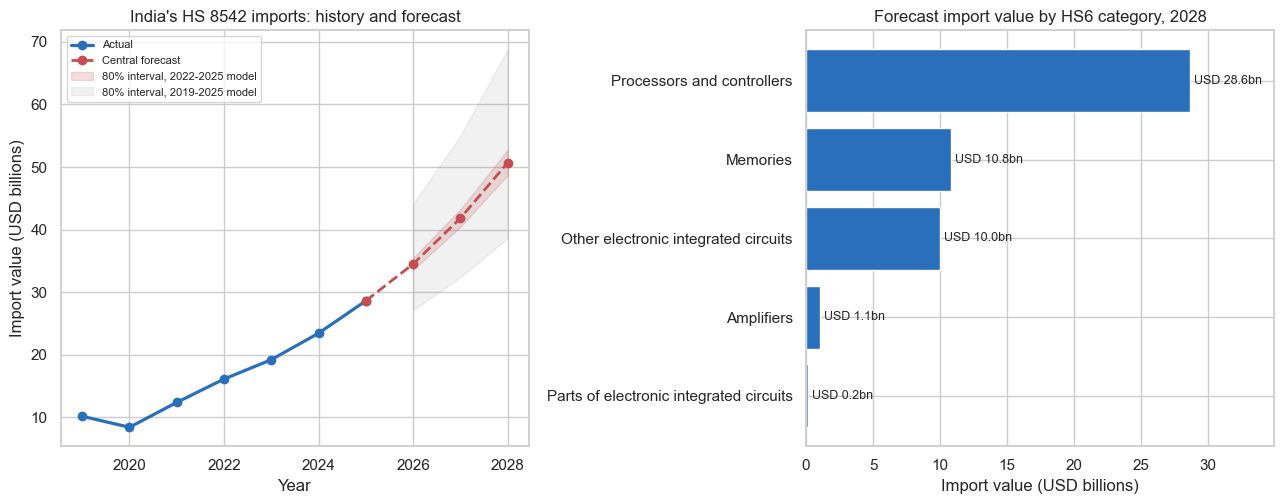

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

ax = axes[0]
ax.plot(
    total_series.index, total_series.values / 1e9,
    marker="o", linewidth=2.3, color="#2a6fbb", label="Actual"
)
forecast_line_years = [2025] + forecast_years
forecast_line_values = [total_series.loc[2025] / 1e9] + (
    total_forecast["forecast_usd"] / 1e9
).tolist()
ax.plot(
    forecast_line_years, forecast_line_values,
    marker="o", linestyle="--", linewidth=2.0, color="#c44e52",
    label="Central forecast"
)
ax.fill_between(
    forecast_years,
    total_forecast["lower_80_usd"] / 1e9,
    total_forecast["upper_80_usd"] / 1e9,
    color="#c44e52", alpha=0.18, label="80% interval, 2022-2025 model"
)
ax.fill_between(
    forecast_years,
    full_period_total["lower_80_usd"] / 1e9,
    full_period_total["upper_80_usd"] / 1e9,
    color="#777777", alpha=0.10, label="80% interval, 2019-2025 model"
)
ax.set(
    title="India's HS 8542 imports: history and forecast",
    xlabel="Year", ylabel="Import value (USD billions)"
)
ax.legend(fontsize=8)

ax = axes[1]
latest_forecast = category_forecasts.loc[
    category_forecasts["year"] == 2028
].sort_values("forecast_usd")
ax.barh(
    latest_forecast["commodity"], latest_forecast["forecast_usd"] / 1e9,
    color="#2a6fbb"
)
for position, (_, row) in enumerate(latest_forecast.iterrows()):
    ax.text(
        row["forecast_usd"] / 1e9 + 0.3, position,
        f"USD {row['forecast_usd'] / 1e9:.1f}bn", va="center", fontsize=9
    )
ax.set(
    title="Forecast import value by HS6 category, 2028",
    xlabel="Import value (USD billions)", ylabel=""
)
ax.set_xlim(0, latest_forecast["forecast_usd"].max() / 1e9 * 1.22)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "import_forecast_2026_2028.png", dpi=180, bbox_inches="tight")
plt.show()

## Predictive findings

The recent-window model puts 2028 imports at **USD 50.67 billion**, equivalent to a **21.0% CAGR** from 2025. The full-period model gives almost the same central value (USD 51.54 billion) but a much wider 80% interval (USD 38.61-68.81 billion), because it includes the 2020 disruption. The recent-window interval (USD 48.69-52.73 billion) is conditional on the post-2022 trend continuing and should not be read as a full planning range. The wider range is the more honest summary of forecast uncertainty.

Processors and controllers account for **USD 28.63 billion (56.5%)** of the 2028 central forecast, followed by memories at **USD 10.81 billion (21.3%)**, other integrated circuits at **USD 10.03 billion (19.8%)**, amplifiers at **USD 1.06 billion (2.1%)**, and parts at **USD 0.18 billion (0.4%)**.

The holdout test trains on 2019-2023 and predicts 2024-2025. The recent-window model has a total MAPE of **4.6%**, compared with 14.0% for a linear trend and 25.4% for a naive last-value forecast. Category errors are larger: processors 9.3%, memories 8.4%, other integrated circuits 6.7%, parts 61.2%, and amplifiers 208.9%. The amplifier and parts forecasts are therefore indicative only; both categories are small and volatile.

# 8. Prescriptive extension

## Prescriptive question

The fourth stage uses **prescriptive analytics through scenario analysis**. It asks:

> If India wants to reduce single-supplier concentration in 2028, what supplier mix would meet a given cap, and how large is the required reallocation?

The analysis treats the 2028 central forecast as fixed demand and the 2025 supplier shares as the baseline mix. A policy cap is applied to supplier shares, and the excess is redistributed pro rata across uncapped suppliers. The scenarios are accounting benchmarks, not procurement plans: they do not include tariffs, logistics costs, supplier capacity, or firm-level contracts.

## 8.1 Scenario construction

In [22]:
total_2028 = float(
    total_forecast.loc[total_forecast["year"] == 2028, "forecast_usd"].iloc[0]
)
supplier_2025 = suppliers.set_index("partner_name")["trade_value_usd"]
baseline_2028 = supplier_2025 / supplier_2025.sum() * total_2028


def allocate_with_caps(baseline_values, caps):
    """Cap suppliers and redistribute the excess pro rata across uncapped suppliers."""
    allocation = baseline_values.astype(float).copy()
    fixed = pd.Series(False, index=allocation.index)
    for _ in range(len(allocation) + 1):
        over = (allocation > caps + 1e-6) & (~fixed)
        if not over.any():
            break
        excess = (allocation[over] - caps[over]).sum()
        allocation[over] = caps[over]
        fixed[over] = True
        free = ~fixed
        if not free.any():
            raise ValueError("The caps are infeasible for this import total.")
        weights = baseline_values[free] / baseline_values[free].sum()
        allocation[free] += excess * weights
    return allocation


infinite_caps = pd.Series(np.inf, index=baseline_2028.index)
scenarios = {
    "Baseline (2025 mix)": infinite_caps,
    "China capped at 30%": infinite_caps.copy(),
    "Every supplier capped at 35%": pd.Series(
        0.35 * total_2028, index=baseline_2028.index
    ),
    "Every supplier capped at 25%": pd.Series(
        0.25 * total_2028, index=baseline_2028.index
    ),
}
scenarios["China capped at 30%"]["China"] = 0.30 * total_2028

scenario_allocations = {
    name: allocate_with_caps(baseline_2028, caps) for name, caps in scenarios.items()
}

## 8.2 Scenario metrics and feasibility

In [23]:
def concentration_summary(values):
    shares = values / values.sum() * 100
    return {
        "hhi": float((shares ** 2).sum()),
        "effective_suppliers": float(1 / ((shares / 100) ** 2).sum()),
        "top_1_share_percent": float(shares.max()),
        "top_3_share_percent": float(shares.nlargest(3).sum()),
        "top_5_share_percent": float(shares.nlargest(5).sum()),
        "suppliers_above_5_percent": int((shares >= 5).sum()),
        "china_share_percent": float(shares.get("China", 0)),
        "other_asia_share_percent": float(shares.get("Other Asia, nes", 0)),
        "korea_share_percent": float(shares.get("Rep. of Korea", 0)),
    }


baseline_cagr = (total_2028 / supplier_2025.sum()) ** (1 / 3) - 1
scenario_rows = []
for name, allocation in scenario_allocations.items():
    row = {"scenario": name, **concentration_summary(allocation)}
    row["total_imports_2028_usd"] = float(allocation.sum())
    row["reallocated_usd"] = float((allocation - baseline_2028).clip(lower=0).sum())
    row["reallocated_share_percent"] = (
        row["reallocated_usd"] / row["total_imports_2028_usd"] * 100
    )
    required_cagr = (allocation / supplier_2025.reindex(allocation.index)) ** (1 / 3) - 1
    material = allocation >= 0.01 * allocation.sum()
    row["max_required_cagr_percent"] = float(required_cagr[material].max() * 100)
    row["max_incremental_cagr_points"] = float(
        (required_cagr[material] - baseline_cagr).max() * 100
    )
    scenario_rows.append(row)

scenario_table = pd.DataFrame(scenario_rows).set_index("scenario")
scenario_table.to_csv(TABLE_DIR / "prescriptive_scenarios_2028.csv")
print(scenario_table.round(2).to_string())

                                  hhi  effective_suppliers  top_1_share_percent  top_3_share_percent  top_5_share_percent  suppliers_above_5_percent  china_share_percent  other_asia_share_percent  korea_share_percent  total_imports_2028_usd  reallocated_usd  reallocated_share_percent  max_required_cagr_percent  max_incremental_cagr_points
scenario                                                                                                                                                                                                                                                                                                                                            
Baseline (2025 mix)          2,752.77                 3.63                40.92                85.05                91.15                          3                40.92                     28.12                16.01       50,667,604,734.04             0.00                       0.00                      20.98       

In [24]:
supplier_history = (
    bilateral.groupby(["year", "partner_name"])["trade_value_usd"].sum().unstack(fill_value=0)
)


def recent_supplier_cagr(series, start_year=2022):
    values = series.loc[start_year:]
    positive = values[values > 0]
    if len(positive) < 2:
        return np.nan
    return (
        (positive.iloc[-1] / positive.iloc[0])
        ** (1 / (positive.index[-1] - positive.index[0]))
        - 1
    ) * 100


recent_cagr = {
    name: recent_supplier_cagr(supplier_history[name])
    for name in supplier_history.columns
}

allocation_rows = []
for name, allocation in scenario_allocations.items():
    frame = pd.DataFrame(
        {
            "scenario": name,
            "partner_name": allocation.index,
            "value_2025_usd": supplier_2025.reindex(allocation.index).values,
            "share_2025_percent": (
                supplier_2025.reindex(allocation.index) / supplier_2025.sum() * 100
            ).values,
            "value_2028_usd": allocation.values,
            "share_2028_percent": (allocation / allocation.sum() * 100).values,
        }
    )
    frame["change_usd"] = frame["value_2028_usd"] - frame["value_2025_usd"]
    frame["required_cagr_2025_2028_percent"] = (
        (frame["value_2028_usd"] / frame["value_2025_usd"]) ** (1 / 3) - 1
    ) * 100
    frame["baseline_cagr_percent"] = baseline_cagr * 100
    frame["incremental_cagr_points"] = (
        frame["required_cagr_2025_2028_percent"] - frame["baseline_cagr_percent"]
    )
    frame["recent_cagr_2022_2025_percent"] = frame["partner_name"].map(recent_cagr)
    allocation_rows.append(frame)

supplier_allocations = pd.concat(allocation_rows, ignore_index=True)
supplier_allocations.to_csv(
    TABLE_DIR / "prescriptive_supplier_allocation_2028.csv", index=False
)

focus = supplier_allocations.loc[
    supplier_allocations["scenario"] == "Every supplier capped at 25%"
].sort_values("value_2028_usd", ascending=False)
print(focus.head(12).to_string(index=False))

                    scenario         partner_name    value_2025_usd  share_2025_percent    value_2028_usd  share_2028_percent       change_usd  required_cagr_2025_2028_percent  baseline_cagr_percent  incremental_cagr_points  recent_cagr_2022_2025_percent
Every supplier capped at 25%                China 11,710,232,694.19               40.92 12,666,901,183.51               25.00   956,668,489.32                             2.65                  20.98                   -18.33                          32.20
Every supplier capped at 25%      Other Asia, nes  8,046,184,379.77               28.12 12,666,901,183.51               25.00 4,620,716,803.74                            16.33                  20.98                    -4.65                          99.36
Every supplier capped at 25%        Rep. of Korea  4,580,707,625.56               16.01 12,666,901,183.51               25.00 8,086,193,557.95                            40.36                  20.98                    19.38            

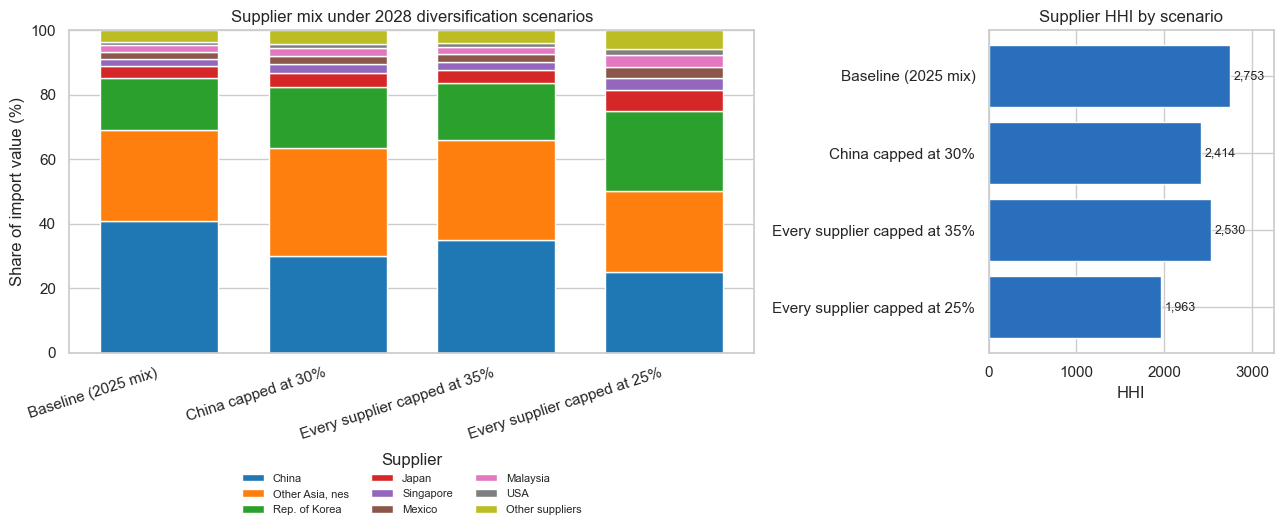

In [25]:
scenario_names = list(scenario_allocations)
top_partners = suppliers.head(8)["partner_name"].tolist()
mix = pd.DataFrame(index=scenario_names)
for partner in top_partners:
    mix[partner] = [
        scenario_allocations[name].get(partner, 0)
        / scenario_allocations[name].sum()
        * 100
        for name in scenario_names
    ]
mix["Other suppliers"] = 100 - mix.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"width_ratios": [2.4, 1]})
ax = axes[0]
colors = sns.color_palette("tab10", n_colors=len(mix.columns))
bottom = np.zeros(len(mix))
for column, color in zip(mix.columns, colors):
    ax.bar(
        range(len(mix)), mix[column], bottom=bottom,
        color=color, label=column, width=0.7
    )
    bottom += mix[column].values
ax.set_xticks(range(len(mix)))
ax.set_xticklabels(scenario_names, rotation=18, ha="right")
ax.set_ylim(0, 100)
ax.set(
    title="Supplier mix under 2028 diversification scenarios",
    xlabel="", ylabel="Share of import value (%)"
)
ax.legend(
    bbox_to_anchor=(0.5, -0.28), loc="upper center",
    ncol=3, fontsize=8, frameon=False, title="Supplier"
)

ax = axes[1]
hhi_values = scenario_table["hhi"].reindex(scenario_names)
bars = ax.barh(range(len(scenario_names)), hhi_values.values, color="#2a6fbb")
ax.set_yticks(range(len(scenario_names)))
ax.set_yticklabels(scenario_names)
ax.invert_yaxis()
for bar, value in zip(bars, hhi_values.values):
    ax.text(
        value + 40, bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}", va="center", fontsize=9
    )
ax.set(title="Supplier HHI by scenario", xlabel="HHI", ylabel="")
ax.set_xlim(0, hhi_values.max() * 1.18)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "prescriptive_scenarios_2028.png", dpi=180, bbox_inches="tight")
plt.show()

## Prescriptive findings

The baseline applies the 2025 supplier mix to the 2028 central forecast. It leaves the HHI at **2,752.8** and the top three suppliers at **85.0%**, so the concentration problem does not fade simply because the market grows.

A targeted cap on China at **30%** lowers the HHI to **2,413.7** and the top-three share to **82.3%**, but it raises `Other Asia, nes` to **33.3%**. Because that label is an unspecified partner, the scenario swaps one concentration risk for another and is not a complete diversification strategy. The required reallocation is **USD 5.53 billion (10.9% of 2028 imports)**, and alternative suppliers would need to grow at **28.0% a year**, about **7.0 percentage points** faster than the baseline path.

A universal **35%** cap lowers the HHI to **2,530.2** and requires **USD 3.00 billion (5.9%)** of reallocation. Alternative suppliers would need **24.9% annual growth**, only **3.9 points** above the baseline. This is the most feasible of the diversification scenarios, but it is a modest improvement: the top three still hold **83.5%**.

A universal **25%** cap is the only scenario that brings the HHI below **2,000** (**1,962.8**) and raises the effective supplier count above five (**5.09**). It requires **USD 9.65 billion (19.0%)** of reallocation, with China growing at only **2.7% a year** and every other material supplier growing at about **43.6% a year**, **22.6 points** above the baseline. That is a step-change in supplier capacity, not a marginal shift.

The prescriptive result is therefore conditional: a **35% cap** is a realistic medium-term diversification target, while a **25% cap** describes the scale of change required for a genuinely diversified supplier base. A targeted China cap is not sufficient on its own because it shifts dependence to `Other Asia, nes`. The scenarios assume that alternative suppliers can scale and that trade is re-routed without cost; they do not include tariffs, logistics, capacity, or firm-level contracts.

# 9. Limitations and next analytics stages

- Trade value is measured in current US dollars; changes can reflect prices and exchange rates as well as physical volume.
- HS six-digit categories remain broad and do not identify individual chip models, manufacturers, fabrication locations, or technology nodes.
- Bilateral trade data identify the declared partner, not every upstream country involved in production.
- `Other Asia, nes` is retained exactly as supplied by Comtrade and is not re-labelled as a specific economy.
- India's original Comtrade classification changes from HS 2017 to HS 2022 in 2022. The five selected codes reconcile to the HS 8542 total in every year, but classification revisions should still be noted.
- Net-weight observations may be estimated or unavailable, so trade value is the primary measure.
- The public API output can be revised by the data provider after retrieval. The metadata file records the retrieval time and query URLs.
- No causal claim is made from descriptive or diagnostic results.
- The predictive model uses four annual observations in its primary window and seven in its sensitivity check. Its intervals describe model fit, not structural breaks, policy changes, or data revisions.
- The prescriptive scenarios hold the 2028 central forecast and the 2025 supplier mix fixed, cap shares by assumption, and redistribute pro rata. They do not model tariffs, logistics costs, supplier capacity, lead times, or firm-level contracts.
- The scenario results are accounting benchmarks, not recommendations for a specific firm or procurement decision.

The project now covers all four analytics types. Further work could add firm-level sourcing data, causal identification of supply-chain disruptions, and a cost-based optimisation that includes tariffs, logistics, and supplier capacity.

# 10. Reproducibility

Run the following commands from the repository root:

```bash
python -m pip install -r requirements.txt
python scripts/data_acquisition.py
```

To rebuild the R Markdown report, open `notebooks/Project_Notebook.Rmd` in RStudio and knit it to HTML. R and the R packages `rmarkdown`, `knitr`, and `reticulate` are required only to render that report; the analysis itself runs in Python. The predictive model uses 2022-2025 as its primary window, and the 2019-2025 model is a sensitivity check. The scenario caps in the prescriptive section are parameters and can be changed to test other policies.

# Key results at a glance

Run this final cell after the analysis to print the headline numbers used in the presentation.

In [26]:
print("2028 import forecast")
print(
    forecast_table.loc[
        forecast_table["year"] == 2028,
        ["commodity", "forecast_usd", "share_of_total_percent", "implied_cagr_2025_2028_percent"],
    ].to_string(index=False)
)

print("\nDiversification scenarios")
print(
    scenario_table[
        ["hhi", "effective_suppliers", "top_3_share_percent", "reallocated_usd", "max_required_cagr_percent"]
    ].round(2).to_string()
)

2028 import forecast
                              commodity      forecast_usd  share_of_total_percent  implied_cagr_2025_2028_percent
         Electronic integrated circuits 50,667,604,734.04                  100.00                           20.98
             Processors and controllers 28,609,855,738.99                   56.47                           19.95
                               Memories 10,803,925,182.64                   21.32                           21.48
                             Amplifiers  1,056,104,501.33                    2.08                           21.55
   Other electronic integrated circuits 10,020,987,336.63                   19.78                           23.17
Parts of electronic integrated circuits    176,731,974.46                    0.35                           40.59

Diversification scenarios
                                  hhi  effective_suppliers  top_3_share_percent  reallocated_usd  max_required_cagr_percent
scenario                      

## Troubleshooting

- **`ModuleNotFoundError`** — select the `.venv` interpreter, or run `.venv\Scripts\python.exe -m pip install -r requirements.txt`.
- **Missing data** — run `.venv\Scripts\python.exe scripts\data_acquisition.py`; it needs internet access.
- **A cell fails after a restart** — run the setup cell and the preceding cells again; the notebook is sequential.
- **The full run is slow** — the pre-built report is available at `reports/Project_Notebook.html`.